In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
import joblib
pd.options.display.float_format='{:.2f}'.format
%matplotlib inline


In [31]:
#df =pd.read_csv('../data/USA_Housing.csv')
df =pd.read_csv('USA_Housing.csv')
df.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.46,5.68,7.01,4.09,23086.80,1059033.56,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64,6.00,6.73,3.09,40173.07,1505890.92,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.07,5.87,8.51,5.13,36882.16,1058987.99,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24,7.19,5.59,3.26,34310.24,1260616.81,USS Barnett\nFPO AP 44820
4,59982.20,5.04,7.84,4.23,26354.11,630943.49,USNS Raymond\nFPO AE 09386


In [32]:
df.columns    
len(df)


5000

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [ ]:
df.describe()

In [ ]:
df.describe().T

In [35]:
#separate feature from label
x =df[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population' ]]
y=df['Price']

In [36]:
# split train test split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print(len(x_train))
print(len(x_test))

4000
1000


In [37]:
#define the model
housing_model=LinearRegression() # Untrained Model




AttributeError: 'LinearRegression' object has no attribute 'intercept_'

In [38]:
housing_model.fit(x_train,y_train)  # Model Training is done here

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [39]:

print(housing_model.coef_)

[2.16522058e+01 1.64666481e+05 1.19624012e+05 2.44037761e+03
 1.52703134e+01]


In [40]:
housing_model.intercept_

np.float64(-2635072.900916771)

In [41]:
feature_importance =housing_model.coef_



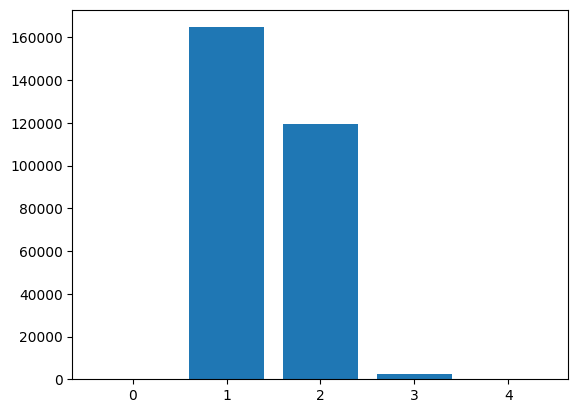

In [56]:
plt.bar([x for x in range(len(feature_importance))], feature_importance)
plt.xticks([x for x in range(len(feature_importance))], x_train.columns.to_list(), rotation=60)
plt.show()

In [44]:
y_hat = housing_model.predict(x_test)
y_hat

array([1308587.92718454, 1237037.2295027 , 1243429.34023036,
       1228900.21368759, 1063320.90731602, 1544058.05050095,
       1094774.70494254,  833284.72338233,  788412.85579609,
       1469714.86611293,  671728.43669856, 1606818.21974717,
       1004166.6133246 , 1796798.97596219, 1288566.96216246,
       1087782.93307671, 1423072.37489045, 1078178.6816464 ,
        802286.03539906,  930761.03707976, 1134829.86484323,
        916398.42014773, 1489972.69333814, 1284580.15551969,
       1582071.35330828, 1132519.16002412, 1089888.39647843,
        974510.51890913,  924057.96821757, 1740759.72095376,
       1286481.59504044, 1621289.95166353, 1435264.20171922,
       1234014.77927044, 1485434.57309075, 1718335.00770333,
       1538953.74887579,  777106.64788454, 1765201.52253623,
       1175972.14217004, 1553707.94311143,  897703.6749909 ,
       1371049.80323147,  845281.72330524, 1201022.89785647,
       1133285.98441204, 1363128.1455284 , 1449814.08776767,
       1574363.90468501,

In [45]:
mse =mean_squared_error(y_test,y_hat)
print(f'MSE: {mse}')

MSE: 10089009299.49946


In [46]:
r2 =r2_score(y_test,y_hat)
r2

0.9179971706985317

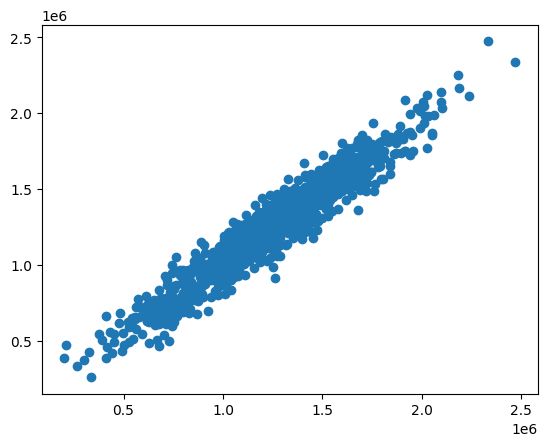

In [47]:
plt.scatter(y_test,y_hat)

In [48]:
plt.savefig('housing_model.png')
print("The model has been saved to disk.")

The model has been saved to disk.


<Figure size 640x480 with 0 Axes>

In [51]:
y=df['Price']
y

0      1059033.56
1      1505890.92
2      1058987.99
3      1260616.81
4       630943.49
          ...    
4995   1060193.79
4996   1482617.73
4997   1030729.58
4998   1198656.87
4999   1298950.48
Name: Price, Length: 5000, dtype: float64

In [52]:
x_new = [[75394.75958, 6.933352468, 7.834099801, 4.48, 22268.07531]] # Comes from CSV (row 1000)
actual = 1498640.551 # Comes from CSV (row 1000)
predictced = housing_model.predict(x_new)[0]

print('actual:', actual)
print('predictced:', predictced)

actual: 1498640.551
predictced: 1427200.5290878424


C:\Ayesha\python\Machine-Learning\Ayesha-Practice\venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [53]:
#Save the model
filename='housing_model.pkl'
joblib.dump(housing_model,filename)
print("Model saved")

Model saved


In [54]:
#load the model
model = joblib.load('housing_model.pkl')
print('Model loaded successfully')

Model loaded successfully


In [55]:
x_new = [[88244.61487, 6.548375433, 8.765481292, 3.36, 25791.99499],
        [79504.65959, 6.505108814, 7.554076285, 4.1, 42677.28492],
        [68267.50282, 5.907275394, 6.800001261, 4.1, 35935.49687]]

actuals = [1788285.239, 1741105.641, 1383938.367]

predictions = model.predict(x_new)

for i in range(len(predictions)):
    print('actual:', actuals[i])
    print('predicted:', predictions[i])
    print('difference:', (actuals[i] - predictions[i]))
    print('--' * 20)

actual: 1788285.239
predicted: 1804529.1523101656
difference: -16243.913310165517
----------------------------------------
actual: 1741105.641
predicted: 1722901.7019848647
difference: 18203.939015135402
----------------------------------------
actual: 1383938.367
predicted: 1187994.6495780284
difference: 195943.71742197173
----------------------------------------


C:\Ayesha\python\Machine-Learning\Ayesha-Practice\venv\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
